# fMRI オープンデータ解析講習：ASD の人と定型発達の人の脳を、デコーディングで比べる

02 では、脳の活動のパターンから「顔条件か図形条件か」を当てました（**デコーディング**）。ここでは同じ方法を、
自閉スペクトラム症（ASD）の研究の問いに使います。

データは、**誤信念課題** の 2 種類の話を読んでいるときの脳の活動です（1 章）。問いは、**定型発達（以下、定型）の人たちの
脳で学習した分類器は、ASD の人の脳からも、どちらの話を読んでいるかを当てられるか** です。当てられれば、2 種類の話を読む
ときの脳の反応の違いが、ASD の人と定型の人で共通していると考えられます。

- **ゴール 4**：定型の人で学習した分類器で ASD の人の話の種類を当て、それが偶然では説明しにくいことを確かめる（4・5 章）

**始める前に**：01・02 のタブで、メニューの「ランタイム」→「ランタイムを接続解除して削除」を選んでから、このノートブックを
実行してください。Colab の無料枠では、同時に使えるメモリなどに限りがあるためです。

### このノートブックの読み方

左に縦線の付いていない文がメインの文章です。左に縦線が付いた「**くわしく**」は、時間があるときや、
あとで読むための部分で、講習の間は読み飛ばしてかまいません。コードは、1 行ずつ読めなくてかまいません。

> **くわしく**（時間があれば）
>
> - 02 を済ませていなくても、このノートブックだけで動きます。分類器や交差検証の説明は 02 より短くしてあります。
> - メインの文章だけを読めば、流れが分かるように書いてあります。
> - Colab での使い方は 01・02 と同じです。セルを選んで Shift + Enter で、上から順に実行します。赤い文字（エラー）が出たら、
>   上のセルを飛ばしていないかを確かめ、メニューの「ランタイム」→「すべてのセルを実行」を試してください。
> - 接続が切れると、取ってきたデータも消えます。そのときも「ランタイム」→「すべてのセルを実行」で、最初からやり直せます。
> - エラーの `NameError` は、たいてい上のセルを実行していないときに出ます。
> - GPU は使いません。

## 0. 準備

脳画像の解析と表示のための Python のライブラリ **Nilearn** を入れます。01・02 と同じバージョンです。
「restart the kernel」という表示が出ても、そのまま次へ進んでかまいません。

0 章の 3 つのセルは、続けて実行するだけでかまいません。

In [ ]:
%pip install -q nilearn==0.13.1

使う道具を読み込みます。

In [ ]:
import socket
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nilearn import plotting, signal
from nilearn.datasets import load_fsaverage, load_fsaverage_data
from nilearn.surface import SurfaceImage, load_surf_data
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.svm import SVC

rng = np.random.default_rng(0)  # 乱数を使うところで、毎回同じ結果になるように
socket.setdefaulttimeout(60)  # 取得の途中で通信が 60 秒止まったら、やり直す

Nilearn が出す注意書きのうち、今回の解析では気にしなくてよいものを表示しないようにします。

In [ ]:
import warnings

warnings.filterwarnings("ignore", message=".*confounds will be standardized.*")

> **くわしく**（時間があれば）
>
> 分類器には、Colab に最初から入っている機械学習のライブラリ **scikit-learn** を使います。

## 1. 課題とデータ

使うのは、OpenNeuro の **ds000212** です。マサチューセッツ工科大学（MIT）で、心の理論と道徳判断を調べる研究のために
集められたデータで、成人の ASD の人と定型の人が参加しています（Koster-Hale et al., 2013）。ここでは、その中の
**誤信念課題** だけを使います。

> **くわしく**（時間があれば）
>
> - データセットのページ：https://openneuro.org/datasets/ds000212 （誰でも自由に使える条件、CC0 で公開されています）
> - スキャナは Siemens の 3 テスラの装置で、2 秒ごとに撮っています。
> - 参加した人は、2 つの課題をしました。1 つは、人が誰かを傷つけるなど、道徳に反するかもしれないことをする話を読み、
>   どのくらい悪いかを 4 段階で答える課題です（わざとした話と、うっかりした話があります）。元の研究の中心はこちらで、
>   5 章の最後の「くわしく」で結果を紹介します。

### 誤信念課題

参加者は、画面に出る短い話を読み、そのあとに出る文が正しいかどうかをボタンで答えます。話は 2 種類です。

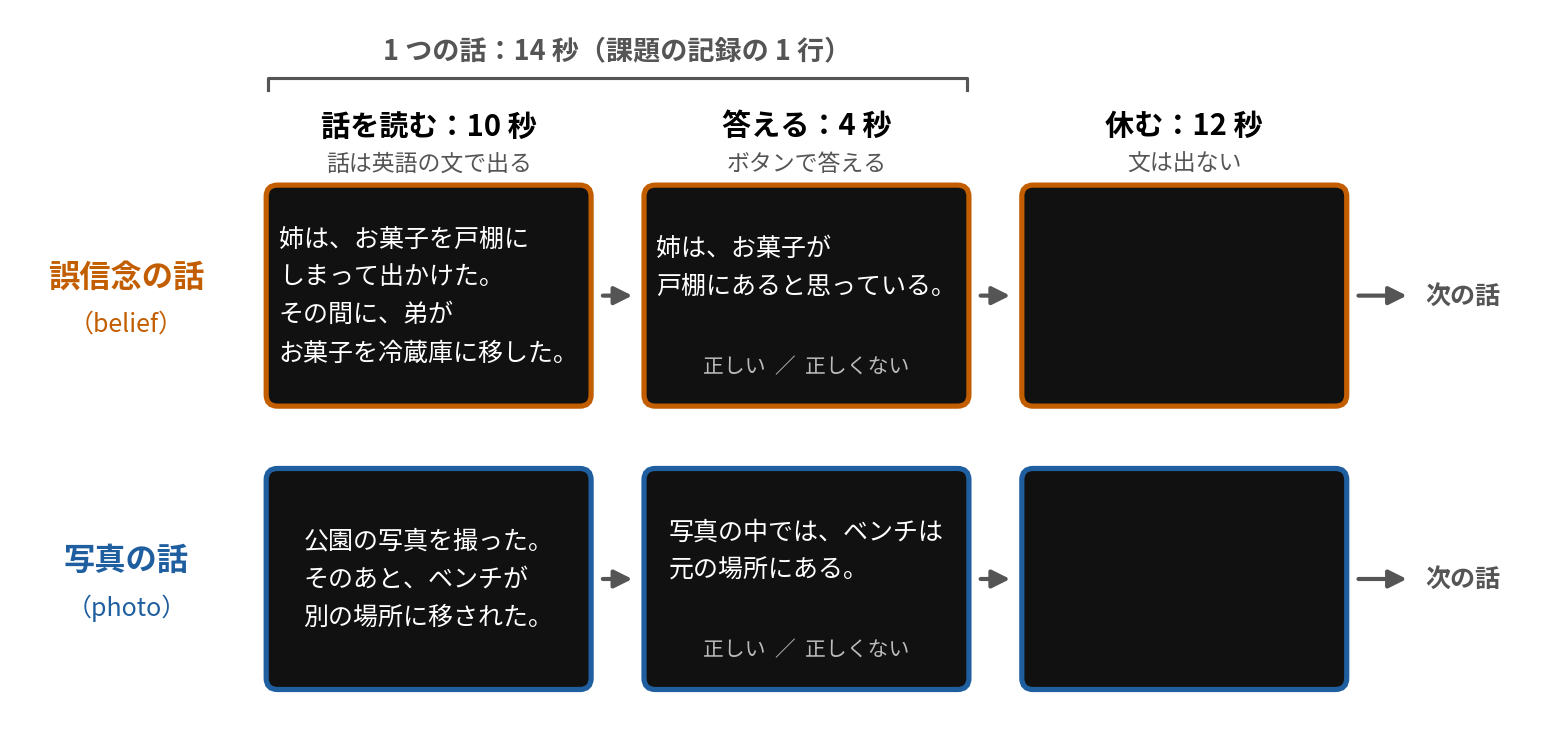

図：1 つの話の流れ。上が誤信念の話、下が写真の話です（画面の文は説明のために作った例で、実際の話は英語です）。

- **誤信念の話（belief）**：登場人物が、事実と違うことを信じるようになる話です。上の例では、姉はお菓子が動かされたことを
  知らないので、まだ戸棚にあると思っています。答えるには、その人の心の中を推し量る必要があります（**心の理論**）。
- **写真の話（photo）**：写真や地図が、古くなって今の様子と違ってしまう話です。下の例では、写真には、ベンチが動かされる前の
  公園が写っています。心ではなく、物の話です。

2 つの話は、どちらも「今の事実と違う中身」（姉の思い込み、古い写真）を頭に置いて答える話で、難しさや長さもそろえてあります。
違うのは、その中身が **人の心の中** にあるか、**物** にあるかです。そこで、2 つの話を読んでいるときの脳の反応を比べると、
人の心の中を考えることに関わる領域が浮かび上がる、と考えます。

1 回の撮像（**run**）の中で、2 種類の話が、休みをはさんで 1 つずつ出ます。

> **くわしく**（時間があれば）
>
> - 誤信念課題は、心の理論に関わる脳の領域を見つけるための標準的な課題として、多くの研究で使われています
>   （Saxe & Kanwisher, 2003; Dodell-Feder et al., 2011）。
> - **答える文**：この課題の標準の手順では、心の中（写真の話では写真の中）のことを聞く文と、今の事実を聞く文
>   （例：「お菓子は今、冷蔵庫にある」）が、同じ数ずつ出ます（Dodell-Feder et al., 2011）。
> - **答え方**：「正しい」か「正しくない」かを、ボタンで答えます。課題の記録には、押したボタンと答えるまでの時間の列もありますが、
>   ボタンが 0（押していない、または記録されていない）になっている記録が多いので、ここでは使いません。
> - 1 つの話は、読む 10 秒と答える 4 秒の 14 秒で、そのあと 12 秒休みます。2 種類の話の順番は、run ごとに決めてあります。
> - 課題の記録では、撮像が始まってから 14 秒後に最初の話が出て、そのあと 26 秒ごとに次の話が出ます。
> - 記録では、1 つの話の 14 秒が 1 行です。話を読む時間と答える時間は分かれていません。
> - 1 run の長さと話の数は、参加した時期によって 2 通りあります。sub-03〜15 の人は 272 秒で 10 話（誤信念 6・写真 4）、
>   sub-16〜35 の人は 220 秒で 8 話（誤信念 6・写真 2）です。

### 予想：どこが反応するか

- 定型の人では、誤信念の話のほうが写真の話より強く反応する場所として、左右の **側頭頭頂接合部**（耳の上の、やや後ろの
  あたり）や **楔前部**（左右の大脳半球が向き合う内側の面の、後ろ寄り）が、くり返し報告されています（Saxe & Kanwisher, 2003; Dodell-Feder et al., 2011）。
- 成人の ASD の人で、これらの場所の反応が定型の人と違うかは、研究によって結果が分かれています（違わない、弱い、強い）。

5 章の最後で、2 つの話の反応の差を脳の表面に描き、この予想と比べます。

> **くわしく**（時間があれば）
>
> - 定型の人では、ほかに **内側前頭前野**（内側の面の、前のほう）と右の **上側頭溝** も、くり返し報告されています。
> - ASD の人は、心の理論に難しさがあると考えられてきました。例えば、ASD の子どもは、人の思い込みを推し量る課題に
>   答えられるようになるのが遅れやすいことが知られています。成人の ASD の人の結果が分かれるのは、人数の少ない研究が
>   多いことが、理由の 1 つと考えられています（Dufour et al., 2013）。
> - 「誤信念の話 − 写真の話」には、人が出てくるかどうかや、使われていることばなど、心の中を考えること以外の違いも
>   含まれます。

### 参加した人たち

参加した人たちの表を取ってきます。`group` が診断（`ASD` または定型の `NT`）です。`NT` は neurotypical の略で、
定型の人を指します。ここでは、39 人のうち、番号が sub-35 までの 30 人を使います（理由は下の「くわしく」）。

In [ ]:
raw_base = "https://s3.amazonaws.com/openneuro.org/ds000212"  # 元のデータ（課題の記録など）
fmriprep_base = "https://openneuro-derivatives.s3.amazonaws.com/fmriprep/ds000212-fmriprep"  # OpenNeuro Derivatives の fMRIPrep の結果

participants = pd.read_csv(f"{raw_base}/participants.tsv", sep="\t").set_index("participant_id")
participants = participants[[int(s[4:]) <= 35 for s in participants.index]]  # sub-38〜47 の 9 人は使わない
participants.groupby("group").agg(people=("age", "size"), mean_age=("age", "mean"),
                                  male=("gender", lambda g: (g == "M").sum()))

ASD の人が 12 人、定型の人が 18 人です。

> **くわしく**（時間があれば）
>
> - このデータセットには、ASD の人 14 人と定型の人 25 人が入っています。sub-38〜47 の 9 人は、ほかの人と違って run が
>   2 つしかなく、課題の記録と撮像の対応が入れ替わっている疑いがあるので、使いません（この教材を作るときに、分類器で調べて
>   気づいたものです。元の実験の記録で確かめたわけではありません）。
> - 外すと決めたのは、その確かめの結果を見てからです。9 人を記録どおりに入れると、定型どうしの正解率は 0.70（この 30 人では
>   0.77）、定型 → ASD は 0.78 で、問いの答えは変わりませんでした（この教材を作るときに調べた値です）。
> - 使う 30 人も、参加した時期によって、run の長さと話の数が 2 通りに分かれています（1 章の「誤信念課題」の「くわしく」）。定型の人の
>   多くは前の時期（sub-03〜15）、ASD の人の多くは後の時期（sub-16〜35）の参加です。同じ時期の人だけで比べても、
>   結論は変わりませんでした（5 章の「くわしく」）。
> - 元の研究によると、ASD の人は、アスペルガー症候群の人の会（Asperger's Association of New England）の広告で募集され、
>   ADOS（面接と観察で ASD の特徴を評価する検査）の点と、診断の基準（DSM-IV）に基づく臨床の判断で ASD と診断された人たちです。
>   知能検査の点の平均は、定型の人と同じくらいでした（Koster-Hale et al., 2013。論文で報告されている人数は、このデータの
>   人数と少し違います）。
> - 後の時期の人では、誤信念の話の記録が、さらに 2 種類（`belief_rep` と `belief_real`）に分かれています。名前からは、答える文が
>   心の中（representation）と今の事実（reality）のどちらを聞くかの違いと考えられますが、データセットに説明はありません。
>   ここではどちらも誤信念の話として扱います。

## 2. データを取ってくる

前処理の済んだデータを、**OpenNeuro Derivatives**（OpenNeuro の前処理のチームが、公開された元のデータにあとから fMRIPrep を
かけて公開しているもの）から取ってきます。**大脳皮質の表面** に写したデータで、01・02 のボクセル（脳を小さな立方体に
区切ったもの）の代わりに、標準の脳の表面に並んだ点（**頂点**）を使います。

30 人分・120 run、合わせて約 1.3 GB を取ってきます。次のセルは、取ってくるファイルの場所と手順を決めます
（実行するだけでかまいません）。

In [ ]:
data_dir = Path("data")
task = "fb"  # ファイル名での、誤信念課題の呼び方
run_numbers = [1, 2, 3, 4]  # 1 人 4 run


def files_of(subject, run):
    """1 run 分の 4 つのファイルについて、取ってくる元（URL）と、置き場所"""
    stem = f"{subject}_task-{task}_run-{run}"
    derived = f"{fmriprep_base}/{subject}/func/{stem}"
    urls = {
        "left": f"{derived}_hemi-L_space-fsaverage5_bold.func.gii",  # 左半球の信号（前処理の結果）
        "right": f"{derived}_hemi-R_space-fsaverage5_bold.func.gii",  # 右半球の信号（前処理の結果）
        "confounds": f"{derived}_desc-confounds_timeseries.tsv",  # 頭の動きなど（前処理の結果）
        "events": f"{raw_base}/{subject}/func/{subject}_task-{task}_run-{run:02d}_events.tsv",  # 課題の記録（元のデータ）
    }
    return {name: (url, data_dir / subject / url.rsplit("/", 1)[1]) for name, url in urls.items()}


def download(url, path):
    """1 つのファイルを取ってくる。すでに取ってあれば取り直さない。通信が切れたら 3 回まで試す"""
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        part = path.with_name(path.name + ".part")  # 途中で切れても壊れたファイルが残らないように
        for attempt in range(3):
            try:
                urllib.request.urlretrieve(url, part)
                break
            except OSError:
                if attempt == 2:
                    raise
        part.rename(path)
    return path

全員分を取ってきます。数分かかります。待つ間に、3 章を読み進めてください。

In [ ]:
jobs = []
for subject in participants.index:
    for run in run_numbers:
        jobs.extend(files_of(subject, run).values())
print(len(jobs), "files")

with ThreadPoolExecutor(max_workers=8) as pool:  # 8 つずつ並行して取ってくる
    paths = list(pool.map(lambda job: download(*job), jobs))
print(f"{sum(p.stat().st_size for p in paths) / 1e9:.2f} GB")

> **くわしく**（時間があれば）
>
> - このデータセットの OpenNeuro のページにあるのは、元のデータ（BIDS）と、画像の質を測った結果（MRIQC）だけです。
>   ここで使うのは、OpenNeuro Preprocessing Team が fMRIPrep（21.0.2）をかけ、別の置き場所にまとめて公開している結果です。
>   01 の 1 章の図でいえば、上の段の「自分でかける前処理」を、別の人たちが代わりにかけて公開してくれたものです。
>   課題の記録（events）は、元のデータから取ります。
> - 表面のデータは、fsaverage5 という標準の脳の形の上に、左右それぞれ 10,242 個の頂点があり、頂点ごとに 2 秒おきの信号が
>   入っています。
> - 1 run あたり 4 つのファイル（左半球、右半球、頭の動きなど、課題の記録）を取ってきます。8 つずつ並行して取ってきます。

## 3. 1 run を「パターン」にする

02 と同じく、1 run から、話の種類ごとに 1 つのパターン（頂点ごとの値の並び）を作ります。まず 1 run 分の信号を読み込み、
時間 × 頂点の表にします（左右の半球をつなげるので、列は 20,484 個です）。

In [ ]:
f = files_of("sub-03", 1)
bold = np.hstack([load_surf_data(f["left"][1]).T, load_surf_data(f["right"][1]).T])
print("table (volumes, vertices):", bold.shape)

課題の記録（events）を見ます。`onset` が話の始まり、`condition` が話の種類です。

In [ ]:
pd.read_csv(f["events"][1], sep="\t")

この人の記録では、`onset` が `[7]` のように、秒ではなく **画像の枚数** で書かれています（2 秒ごとに撮るので、7 枚分で 14 秒）。
そこで、記録を読み、`onset` を秒にそろえ、話の種類を `belief` と `photo` の 2 つにまとめる関数を作ります
（実行するだけでかまいません）。

In [ ]:
t_r = 2.0  # 撮る間隔（秒）


def load_events(path):
    """課題の記録を読み、onset を秒にそろえ、話の種類を belief と photo にまとめる"""
    raw = pd.read_csv(path, sep="\t")
    text = raw["onset"].astype(str)
    onset = text.str.extract(r"(\d+\.?\d*)")[0].astype(float)  # 「[7]」や「[7][7]」から最初の数を取り出す
    onset[text.str.startswith("[")] *= t_r  # [ ] つきは何枚目かなので、秒に直す
    kind = raw["condition"].str.split("_").str[0]  # belief_rep と belief_real は belief に、photo_rep は photo に
    return pd.DataFrame({"onset": onset, "duration": 14.0, "kind": kind})


load_events(f["events"][1])

> **くわしく**（時間があれば）
>
> - 秒で書かれたほかの人の記録でも、最初の話は 14 秒なので、枚数と読むと合います。`duration` の 7 も枚数です。
> - ほかの人には、秒で書かれた記録もあります。公開データでは、このように人によって記録の形が違うことがよくあります。
> - 話と質問を合わせた 14 秒を、1 つの話の時間としています。

パターンは、02 と同じやり方で作ります。血流の遅れを考えて話の時間を **6 秒** 後ろにずらし、同じ run の中の、同じ種類の話の
画像をすべて平均します。図の帯が話を出していた時間（オレンジ：誤信念、青：写真）、点が平均に使う画像の時刻です。

In [ ]:
delay = 6.0  # 血流の遅れ（秒）
skip = 2  # 話の最初に使わない画像の枚数


def volumes_of(events, kind, n_volumes):
    """ある種類の話について、平均に使う画像の番号"""
    times = np.arange(n_volumes) * t_r - delay  # 各画像の時刻を、遅れの分だけ前にずらしたもの
    volumes = []
    for onset in events.loc[events["kind"] == kind, "onset"]:
        volumes.extend(np.where((times >= onset) & (times < onset + 14.0))[0][skip:])
    return np.array(volumes, dtype=int)


events = load_events(f["events"][1])
colors = {"belief": "tab:orange", "photo": "tab:blue"}
fig, ax = plt.subplots(figsize=(10, 1.5))
for kind, color in colors.items():
    for onset in events.loc[events["kind"] == kind, "onset"]:
        ax.axvspan(onset, onset + 14, color=color, alpha=0.3)
    volumes = volumes_of(events, kind, len(bold))
    ax.scatter(volumes * t_r, np.zeros(len(volumes)), color=color, s=12)
ax.set_xlim(0, len(bold) * t_r)
ax.set_yticks([])
ax.set_xlabel("time (s)")
plt.show()

> **くわしく**（時間があれば）
>
> - 頭の動きで説明できる変化と、ゆっくりした直線的な変化を取り除き、頂点ごとに平均 0、標準偏差 1 にそろえています。
> - 6 秒ずらしたあとも、話の最初の 2 枚は、反応がまだ上がりきっていないので使いません。点が帯より右にずれているのは、
>   この 6 秒と、最初の 2 枚の分です。

ここまでを、1 run から 2 つのパターンを作る関数にまとめます（実行するだけでかまいません）。

In [ ]:
motion_columns = ["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z"]


def run_patterns(f):
    """1 run から、誤信念の話と写真の話の平均のパターンを 1 つずつ返す。撮像が途中で止まった run では None を返す"""
    bold = np.hstack([load_surf_data(f["left"][1]).T, load_surf_data(f["right"][1]).T]).astype(float)
    if len(bold) < 50:
        return None, len(bold), None
    motion = pd.read_csv(f["confounds"][1], sep="\t")[motion_columns]
    table = signal.clean(bold, detrend=True, standardize="zscore_sample", confounds=motion.to_numpy(), t_r=t_r)
    events = load_events(f["events"][1])
    patterns = {kind: table[volumes_of(events, kind, len(table))].mean(axis=0) for kind in ("belief", "photo")}
    return patterns, len(table), bold.mean(axis=0) > 0

全員の全部の run で、パターンを作ります。1〜2 分かかります。

In [ ]:
rows, belief, photo = [], [], []
has_signal = True
for subject in participants.index:
    for run in run_numbers:
        patterns, n_volumes, signal_here = run_patterns(files_of(subject, run))
        if patterns is None:
            print(f"\nskip {subject} run {run} ({n_volumes} volumes)")
            continue
        has_signal = has_signal & signal_here
        rows.append({"subject": subject, "run": run, "group": participants.loc[subject, "group"]})
        belief.append(patterns["belief"])
        photo.append(patterns["photo"])
    print(subject, end=" ")

runs = pd.DataFrame(rows)
belief, photo = np.array(belief)[:, has_signal], np.array(photo)[:, has_signal]
print()
print("runs:", len(runs), "/ vertices used:", int(has_signal.sum()))

> **くわしく**（時間があれば）
>
> - `sub-32` の run 3 は、17 枚で撮像が止まっているので使いません。
> - 全員のすべての run で信号がある頂点だけを、あとで使います（脳の内側の、皮質がない部分などを除くため）。

## 4. 定型の人どうしで、話の種類を当てる

まず、02 と同じことを定型の 18 人でします。1 人をテスト用に除き、残りの 17 人で学習した分類器（線形 SVM）で、
その人の各 run のパターンが誤信念の話か写真の話かを当てます。これを 1 人ずつ入れ替えて全員にします（1 人除きの交差検証）。

In [ ]:
def make_table(rows):
    """選んだ run の、パターンの表 X、正解 y、誰のデータか groups"""
    X = np.vstack([np.vstack([b, p]) for b, p in zip(belief[rows], photo[rows])])  # run ごとに belief、photo の順
    y = np.tile(["belief", "photo"], rows.sum())
    groups = np.repeat(runs.loc[rows, "subject"].to_numpy(), 2)
    return X, y, groups


svm = SVC(kernel="precomputed", C=1.0)
X_nt, y_nt, groups_nt = make_table((runs["group"] == "NT").to_numpy())
K_nt = X_nt @ X_nt.T
splits = list(LeaveOneGroupOut().split(K_nt, y_nt, groups=groups_nt))  # 1 人除きの分け方
predicted = cross_val_predict(svm, K_nt, y_nt, cv=splits)
accuracy_nt = pd.Series(predicted == y_nt).groupby(groups_nt).mean()  # 1 人ずつの正解率
print("examples:", X_nt.shape, "/ mean accuracy:", accuracy_nt.mean().round(3))

> **くわしく**（時間があれば）
>
> 02 と同じく、パターンどうしの内積の表を先に作って、計算を速くしています（`kernel="precomputed"`）。関数 `make_table` は、
> パターンの表と正解と「誰のデータか」をまとめて作ります。

1 人ずつの正解率を、棒で並べます。

In [ ]:
def plot_accuracy(accuracy, title, color):
    """1 人ずつの正解率を棒にする"""
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.bar(accuracy.index, accuracy, color=color)
    ax.axhline(0.5, color="gray", linestyle="--")
    ax.set_ylabel("accuracy")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=90)
    plt.show()


plot_accuracy(accuracy_nt, f"NT, leave one person out ({len(accuracy_nt)} people)", "tab:blue")

02 の顔と図形ほどではありませんが、多くの人で偶然（0.5）よりよく当たります。

偶然でもこのくらい当たるかを、02 と同じく、**人ごとに** 誤信念と写真のラベルを入れ替えるかどうかをでたらめに決める
並べ替え検定で確かめます（500 回、30 秒ほど）。

In [ ]:
def flip_people(labels, groups):
    """人ごとに、その人の全部の run で誤信念と写真のラベルを入れ替えるかどうかを、でたらめに決める"""
    flip = {s: rng.random() < 0.5 for s in np.unique(groups)}
    swapped = np.where(labels == "belief", "photo", "belief")
    return np.where([flip[g] for g in groups], swapped, labels)


def mean_accuracy_nt(labels):
    """定型どうしの 1 人除きの交差検証で、1 人ずつの正解率の平均"""
    predicted = cross_val_predict(svm, K_nt, labels, cv=splits)
    return pd.Series(predicted == labels).groupby(groups_nt).mean().mean()


null_scores = np.array([mean_accuracy_nt(flip_people(y_nt, groups_nt)) for _ in range(500)])
p_value = (np.sum(null_scores >= accuracy_nt.mean()) + 1) / (len(null_scores) + 1)
print("accuracy:", accuracy_nt.mean().round(3), "/ flipped labels: mean", null_scores.mean().round(3),
      "max", null_scores.max().round(3), "/ p =", round(p_value, 4))

> **くわしく**（時間があれば）
>
> - 知りたいのは、**人をまたいで共通する** 誤信念と写真の違いがあるかです。人をまたいで共通する違いが無ければ、誰のラベルを
>   入れ替えても、同じくらい当たるはずです。1 人の中でばらばらにラベルを混ぜると、1 人の中では一貫していても人をまたいでは
>   共通しない違いまで壊してしまい、p 値が小さく出すぎることがあります。
> - 入れ替えるたびに、同じ 1 人除きの交差検証をやり直しています。p 値は「入れ替えたのに本物と同じかそれ以上当たった回数 ＋ 1」を
>   「500 ＋ 1」で割ったものです。

入れ替えたラベルでは、本物ほど当たることはほとんどありません。定型の人どうしでは、人をまたいで共通する、誤信念の話と
写真の話を読むときの反応の違いがあると言えます。

## 5. 問い：定型の人で学習した分類器は、ASD の人にも効くか

いよいよ問いです。**定型の人全員** で学習し、学習に一度も使っていない **ASD の人** を当てます。

In [ ]:
X_asd, y_asd, groups_asd = make_table((runs["group"] == "ASD").to_numpy())
svm_lin = SVC(kernel="linear", C=1.0).fit(X_nt, y_nt)  # 学習したものをそのまま使うので、ここは内積の表を作らない
predicted_asd = svm_lin.predict(X_asd)
accuracy_asd = pd.Series(predicted_asd == y_asd).groupby(groups_asd).mean()
plot_accuracy(accuracy_asd, f"ASD, classifier trained on all NT ({len(accuracy_asd)} people)", "tab:red")
print("mean accuracy:", accuracy_asd.mean().round(3))

これも、人ごとにラベルを入れ替える並べ替え検定で確かめます（分類器の答えはそのままにして、1000 回）。

In [ ]:
null_asd = np.array([pd.Series(predicted_asd == flip_people(y_asd, groups_asd)).groupby(groups_asd).mean().mean()
                     for _ in range(1000)])
print("flipped labels: mean", null_asd.mean().round(3), "max", null_asd.max().round(3),
      "/ p =", round((np.sum(null_asd >= accuracy_asd.mean()) + 1) / (len(null_asd) + 1), 4))

定型の人どうし（1 人除き）と、定型 → ASD の正解率を比べます。差がどのくらい揺れうるかの、おおまかな参考範囲も出します
（**ブートストラップ**）。

In [ ]:
difference = accuracy_asd.mean() - accuracy_nt.mean()
boot = [rng.choice(accuracy_asd, len(accuracy_asd)).mean() - rng.choice(accuracy_nt, len(accuracy_nt)).mean()
        for _ in range(5000)]
print(f"NT (leave one out) {accuracy_nt.mean():.3f} / NT -> ASD {accuracy_asd.mean():.3f}")
print(f"difference {difference:+.3f} (bootstrap range {np.percentile(boot, 2.5):+.3f} to {np.percentile(boot, 97.5):+.3f})")

> **くわしく**（時間があれば）
>
> - ブートストラップでは、同じ人数を重複を許して選び直しては差を計算し直すことを、5000 回繰り返します。分類器の答えはそのままにして、どの人を数えるかだけを変えています。学習し直すことによる揺れは入っていないので、
>   参考範囲はおおまかなものです。
> - 定型の人の多くは前の時期（sub-03〜15）、ASD の人の多くは後の時期（sub-16〜35）の参加なので、同じ後の時期の人だけでも
>   比べました。定型の人 0.68（6 人）、ASD の人 0.78（11 人）で、ASD の人のほうが当たりにくいということはありませんでした
>   （この教材を作るときに調べた値です）。

差は小さく、参考範囲は 0 をはさんで ±0.1 くらいに広がっています。定型の人の脳で学んだ「誤信念の話を読むときの反応」は、
ASD の人でも、定型どうしとほぼ同じくらい当たりました。ただし、0.1 くらいの差があってもおかしくないので、
「同じ」とまでは言えません。

ここまでで、定型 → ASD の正解率と p 値が出ていれば、**ゴール 4** 達成です。

**誤信念と写真の反応の差の地図** も見ておきます。人ごとに「誤信念のパターン − 写真のパターン」を run で平均し、1 人 1 枚の地図にします。

In [ ]:
maps = np.vstack([(belief - photo)[(runs["subject"] == s).to_numpy()].mean(axis=0) for s in participants.index])  # 1 人 1 枚
diagnosis = participants["group"].to_numpy()
print("maps (people, vertices):", maps.shape)

定型と ASD のそれぞれで、頂点ごとに、人をまたいで 0 と違うかを t 値にして、脳の表面に描きます。赤は誤信念 > 写真、
青は写真 > 誤信念です（t の絶対値が 3 より大きい頂点に色を付けた目安です）。

**図の見方**：脳の表面をふくらませて、溝の中まで見えるようにしています。lateral は外側から、medial は内側から見た図です。

In [ ]:
def one_sample_t(A):
    """頂点ごとの、人をまたいだ t 値"""
    return A.mean(axis=0) / (A.std(axis=0, ddof=1) / np.sqrt(len(A)))


fsaverage = load_fsaverage("fsaverage5")
sulcal = load_fsaverage_data(mesh="fsaverage5", data_type="sulcal", mesh_type="inflated")


def to_surface(values):
    """使った頂点の値を、脳の表面の画像に戻す"""
    full = np.zeros(len(has_signal))
    full[has_signal] = values
    return SurfaceImage(mesh=fsaverage["inflated"], data={"left": full[:10242], "right": full[10242:]})


t_maps = {name: one_sample_t(maps[diagnosis == name]) for name in ("NT", "ASD")}
fig, axes = plt.subplots(2, 4, figsize=(16, 7), subplot_kw={"projection": "3d"})
for row, name in enumerate(t_maps):
    for col, (hemi, view) in enumerate([("left", "lateral"), ("left", "medial"), ("right", "lateral"), ("right", "medial")]):
        plotting.plot_surf_stat_map(stat_map=to_surface(t_maps[name]), surf_mesh=fsaverage["inflated"], hemi=hemi,
                                    view=view, bg_map=sulcal, threshold=3.0, vmax=8, axes=axes[row, col], figure=fig,
                                    colorbar=(col == 3), title=f"{name} (n={(diagnosis == name).sum()}) {hemi} {view}")
plt.show()
print("correlation between the NT and ASD t maps:", np.corrcoef(t_maps["NT"], t_maps["ASD"])[0, 1].round(2))

定型でも ASD でも、側頭頭頂接合部（耳の上のあたり、外側の図の後ろ寄り）と楔前部（内側の図の後ろ寄り）に赤い領域が出ます。
心の理論の課題でよく報告される場所です。

**問いの答え**：このデータでは、定型の人で学習した分類器は、ASD の人でも、定型どうしとほぼ同じくらい当たりました。
反応の差の地図も、同じような場所に出ます。

> **くわしく**（時間があれば）
>
> - 色を付ける目安（t の絶対値が 3 より大きい）は見比べるためのもので、多重比較の補正はしていません。これは分類器の重みの
>   地図ではなく、2 種類の話への反応の、平均の差の地図です。
> - 外側の図は、左半球では左が前、右半球では右が前です。内側の図はその逆です。灰色の濃淡は、ふくらませる前の溝と山の
>   位置を表します。
> - ASD のほうが色の付く範囲が狭いのは、人数が少なく、t 値が小さくなりやすいためでもあります。
> - 最後に表示した、定型と ASD の地図の相関（頂点をまたいだ相関）0.43 は、赤が出る主な場所は共通しているものの、
>   頂点ごとの細かな値までは一致していない、という程度です。
> - 大規模な研究（定型 462 人、ASD 31 人）でも、この課題の脳の反応に群の差は見つかっていません（Dufour et al., 2013）。
> - 一方、このデータの元の研究は、別の課題（わざと与えた害か、うっかり与えた害か）で、定型の人では右の側頭頭頂接合部の
>   パターンから意図を読み取れたのに、ASD の人では読み取れなかったと報告しています（Koster-Hale et al., 2013）。
>   「心の理論の領域が働くか」と「その中にどんな情報があるか」は、別の問いです。

## 6. まとめ

- **定型の人で学習した分類器を ASD の人に当てる** と、2 つの話を読むときの反応の違いが、ASD の人にも共通しているかを
  確かめられます。
- **差が見つからないことは、差が無いことではありません**。正解率の差の参考範囲は ±0.1 くらいに広がっていました。
  小さな差が無いと言うには、もっと多くの人が要ります。

次の 04 では、問いを変えて、脳から **その人が** ASD か定型かを当てられるかを、ずっと多くの人のデータで調べます。

> **くわしく**（時間があれば）
>
> **調べたことと結果**
>
> - **定型の人どうし（1 人除き）**：0.77。偶然より高い（人ごとにラベルを入れ替える並べ替え検定）
> - **定型の人で学習して ASD の人を当てる**：0.78。偶然より高い。定型どうしとの差は +0.01（参考範囲 −0.09〜+0.12）
> - **誤信念 − 写真の反応の差の地図**：どちらの群でも、側頭頭頂接合部と楔前部に出た

## 7. 自分で試してみよう

セルを書き換えて試せます。時間があれば試してください（持ち帰って試してもかまいません）。

> **くわしく**（時間があれば）
>
> 1. 問いを逆向きにする：ASD の人で学習し、定型の人を当てる（下のセル）。ASD の人は定型の人より少ないので、学習に使える人数が
>    少ない点にも注意します。
> 2. 5 章の地図を、誤信念のパターンだけ（写真を引かない）にする。5 章の地図を作るセルの `maps = ...` の行を
>    `maps = np.vstack([belief[(runs["subject"] == s).to_numpy()].mean(axis=0) for s in participants.index])` に書き換え、
>    そのセルから下を順に実行し直します（t 値の図が、誤信念 − 写真ではなく、誤信念の話への反応の地図に変わります）。
> 3. 3 章の `delay = 6.0` を `0.0`（血流の遅れを考えない）にして、そのセルから下を順に実行し直す。

In [ ]:
svm_from_asd = SVC(kernel="linear", C=1.0).fit(X_asd, y_asd)
accuracy_from_asd = pd.Series(svm_from_asd.predict(X_nt) == y_nt).groupby(groups_nt).mean()
print("ASD -> NT: mean accuracy", accuracy_from_asd.mean().round(3))

## 8. 使った環境を記録する

今回の解析に使った Python と道具のバージョンを表示します。

In [ ]:
import sys

import nilearn
import sklearn

print("Python:", sys.version.split()[0])
print("nilearn:", nilearn.__version__)
print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)

## データと道具、方法の出典

- データ：Koster-Hale, J., Saxe, R., Dungan, J., & Young, L. L. (2013). Decoding moral judgments from neural
  representations of intentions. *PNAS*, 110, 5648–5653. https://doi.org/10.1073/pnas.1207992110
  （OpenNeuro ds000212、CC0。前処理済みのデータは OpenNeuro Derivatives の `ds000212-fmriprep`、fMRIPrep 21.0.2、CC0、
  https://github.com/OpenNeuroDerivatives ）
- 課題：Saxe, R., & Kanwisher, N. (2003). People thinking about thinking people: The role of the temporo-parietal junction
  in "theory of mind". *NeuroImage*, 19, 1835–1842. https://doi.org/10.1016/s1053-8119(03)00230-1
- 課題：Dodell-Feder, D., Koster-Hale, J., Bedny, M., & Saxe, R. (2011). fMRI item analysis in a theory of mind task.
  *NeuroImage*, 55, 705–712. https://doi.org/10.1016/j.neuroimage.2010.12.040
- 群の比較：Dufour, N., Redcay, E., Young, L., Mavros, P. L., Moran, J. M., Triantafyllou, C., Gabrieli, J. D. E., & Saxe, R.
  (2013). Similar brain activation during false belief tasks in a large sample of adults with and without autism.
  *PLoS One*, 8, e75468. https://doi.org/10.1371/journal.pone.0075468
- 前処理：Esteban, O., et al. (2019). fMRIPrep: a robust preprocessing pipeline for functional MRI.
  *Nature Methods*, 16, 111–116. https://doi.org/10.1038/s41592-018-0235-4
- 解析：Nilearn https://nilearn.github.io/ 、scikit-learn https://scikit-learn.org/
- 並べ替え検定：Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance.
  *Journal of Machine Learning Research*, 11, 1833–1863.